# Lab 2 — Unsupervised Learning + Evaluation Story

**Goal:** practice clustering + PCA *and* learn how to communicate results with a defensible evaluation story.

**You will:**
- clean + preprocess mixed-type data using `sklearn` Pipelines
- run K-Means for multiple K values
- justify K using *at least* 2 signals (e.g., inertia elbow + silhouette)
- interpret clusters (give them names + show 2–3 distinguishing features)
- use PCA for 2D visualization and explain explained variance
- write a short memo outline (template provided)

**Important rule:** do **not** use `purchase` or `spend_usd` as training features for clustering.


In [1]:
# If running locally, install requirements first:
# pip install -r ../requirements.txt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


## 1) Load data

In [2]:
data_path = "./data/ecommerce_sessions.csv"
df = pd.read_csv(data_path)
df.head()


,session_id,country,device_type,traffic_source,session_minutes,pages_viewed,avg_scroll_depth,items_added_to_cart,prior_visits_30d,purchase,spend_usd,event_time
0,S100000,IN,mobile,search,4.516530,7,0.514905,1,4,1,54.57,2025-10-03 17:24:00
1,S100001,TR,desktop,search,0.962363,5,0.473726,4,0,1,58.80,2025-10-15 00:44:00
2,S100002,US,mobile,social,6.869928,7,0.700772,1,2,0,0.00,2025-10-05 22:51:00
3,S100003,DE,desktop,search,5.087378,8,0.527164,0,2,1,47.91,2025-10-14 16:58:00
4,S100004,KZ,desktop,direct,5.179733,7,0.636064,0,3,0,0.00,2025-09-05 05:44:00


## 2) Quick EDA (5 minutes)

Do a quick check:
- shape, missing values
- distributions of key numeric columns
- sanity-check ranges

**TODO:** Add 2 quick plots (histogram/boxplot) for any two numeric columns.


In [3]:
df.shape, df.isna().mean().sort_values(ascending=False).head(10)


((1800, 12),
 avg_scroll_depth       0.031667
 session_minutes        0.029444
 session_id             0.000000
 country                0.000000
 device_type            0.000000
 traffic_source         0.000000
 pages_viewed           0.000000
 items_added_to_cart    0.000000
 prior_visits_30d       0.000000
 purchase               0.000000
 dtype: float64)

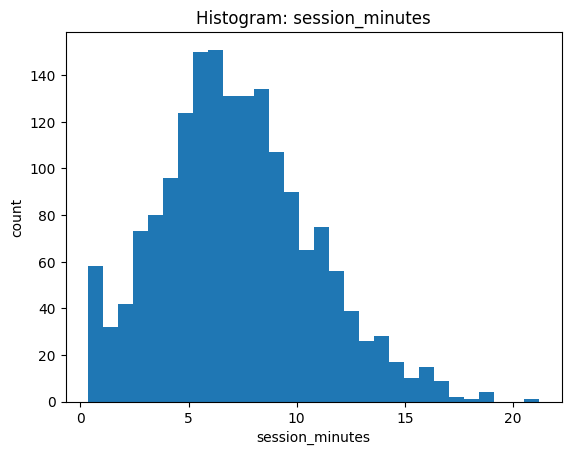

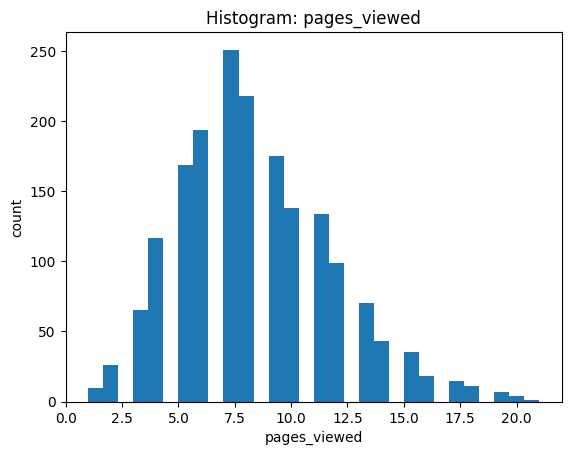

In [4]:
# TODO: pick two numeric columns and plot histograms
num_cols_preview = ["session_minutes","pages_viewed","avg_scroll_depth","items_added_to_cart","prior_visits_30d"]
for col in ["session_minutes","pages_viewed"]:
    plt.figure()
    plt.hist(df[col].dropna(), bins=30)
    plt.title(f"Histogram: {col}")
    plt.xlabel(col)
    plt.ylabel("count")
    plt.show()


## 3) Define features for clustering

We'll cluster *behavioral sessions*.

**DO NOT include labels in X:**
- `purchase`
- `spend_usd`

Also, `session_id` is an identifier → exclude it.
`event_time` is a timestamp; you may exclude it (recommended for this lab).


In [5]:
drop_cols = ["session_id","purchase","spend_usd","event_time"]
X = df.drop(columns=drop_cols)
X.columns


Index(['country', 'device_type', 'traffic_source', 'session_minutes',
       'pages_viewed', 'avg_scroll_depth', 'items_added_to_cart',
       'prior_visits_30d'],
      dtype='str')

## 4) Preprocessing with Pipeline

**Why pipelines?** Reproducibility and no “training/test mismatch”.

Steps:
- numeric: impute (median) + scale
- categorical: impute (most_frequent) + one-hot encode


In [6]:
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

preprocessor


/var/folders/hh/038yvty53_j0vqjm7w3g3j9c0000gn/T/ipykernel_98365/1262883926.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object"]).columns.tolist()


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 5) Choose K: elbow + silhouette

We’ll compare K from 2 to 10.

**TODO:** Decide your final K and justify it in 2–4 sentences.

Notes:
- Inertia decreases with K; look for a “knee”.
- Silhouette score (higher is better) measures separation/cohesion.


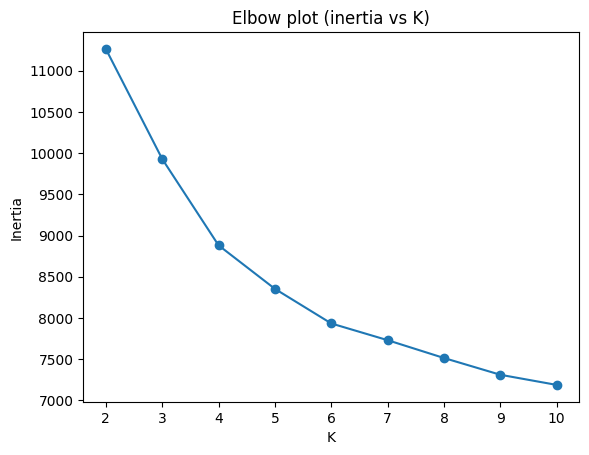

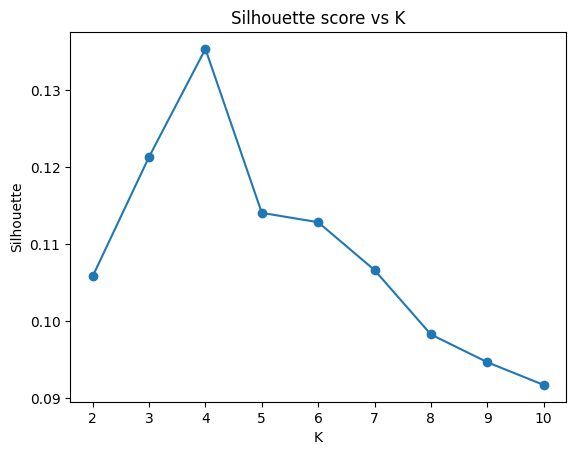

[(2, np.float64(0.106)),
 (3, np.float64(0.121)),
 (4, np.float64(0.135)),
 (5, np.float64(0.114)),
 (6, np.float64(0.113))]

In [7]:
Ks = list(range(2, 11))
inertias = []
silhouettes = []

Xp = preprocessor.fit_transform(X)

for k in Ks:
    km = KMeans(n_clusters=k, random_state=42, n_init="auto")
    labels = km.fit_predict(Xp)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(Xp, labels))

# Plot inertia
plt.figure()
plt.plot(Ks, inertias, marker="o")
plt.title("Elbow plot (inertia vs K)")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.show()

# Plot silhouette
plt.figure()
plt.plot(Ks, silhouettes, marker="o")
plt.title("Silhouette score vs K")
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.show()

list(zip(Ks, np.round(silhouettes, 3)))[:5]


## 6) Fit final K-Means model and inspect clusters

**TODO:**
- choose `K_FINAL`
- show cluster sizes
- interpret clusters using:
  - mean numeric values by cluster (in original units)
  - top categorical proportions by cluster


In [8]:
K_FINAL = 4  # TODO: change based on your justification

kmeans = KMeans(n_clusters=K_FINAL, random_state=42, n_init="auto")

model = Pipeline(steps=[
    ("prep", preprocessor),
    ("kmeans", kmeans)
])

cluster_labels = model.fit_predict(X)
df["cluster"] = cluster_labels

df["cluster"].value_counts().sort_index()


cluster
0    506
1    337
2    198
3    759
Name: count, dtype: int64

In [9]:
# Numeric interpretation (means by cluster)
num_cols = ["session_minutes","pages_viewed","avg_scroll_depth","items_added_to_cart","prior_visits_30d"]
df.groupby("cluster")[num_cols].mean().round(2)


,session_minutes,pages_viewed,avg_scroll_depth,items_added_to_cart,prior_visits_30d
cluster,,,,,
0,10.25,11.66,0.55,1.03,2.51
1,6.71,7.61,0.73,4.02,2.62
2,5.73,6.92,0.47,1.16,11.14
3,5.86,6.62,0.53,1.08,2.47


In [10]:
# Categorical interpretation (proportions by cluster)
for col in ["device_type","traffic_source","country"]:
    print(f"\n--- {col} ---")
    display(
        (df.groupby("cluster")[col]
         .value_counts(normalize=True)
         .rename("share")
         .reset_index()
         .sort_values(["cluster","share"], ascending=[True, False])
         .groupby("cluster")
         .head(3))
    )



--- device_type ---


,cluster,device_type,share
0,0,mobile,0.620553
1,0,desktop,0.318182
2,0,tablet,0.061265
3,1,mobile,0.623145
4,1,desktop,0.335312
5,1,tablet,0.041543
6,2,mobile,0.611111
7,2,desktop,0.343434
8,2,tablet,0.045455
9,3,mobile,0.642951



--- traffic_source ---


,cluster,traffic_source,share
0,0,search,0.403162
1,0,social,0.233202
2,0,referral,0.158103
5,1,search,0.370920
6,1,social,0.240356
7,1,direct,0.154303
10,2,search,0.404040
11,2,social,0.237374
12,2,referral,0.146465
15,3,search,0.418972



--- country ---


,cluster,country,share
0,0,KZ,0.349802
1,0,TR,0.146245
2,0,US,0.118577
7,1,KZ,0.364985
8,1,TR,0.151335
9,1,IN,0.106825
14,2,KZ,0.297980
15,2,TR,0.146465
16,2,DE,0.136364
21,3,KZ,0.363636


## 7) PCA visualization (2D)

We’ll project preprocessed features to 2 dimensions for visualization.

**TODO:**
- report explained variance ratio for PC1+PC2
- make a scatter plot of PC1 vs PC2 colored by cluster


In [11]:
Xp = preprocessor.fit_transform(X)
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(Xp)

evr = pca.explained_variance_ratio_
evr, evr.sum()


(array([0.18874018, 0.17956406]), np.float64(0.3683042393794165))

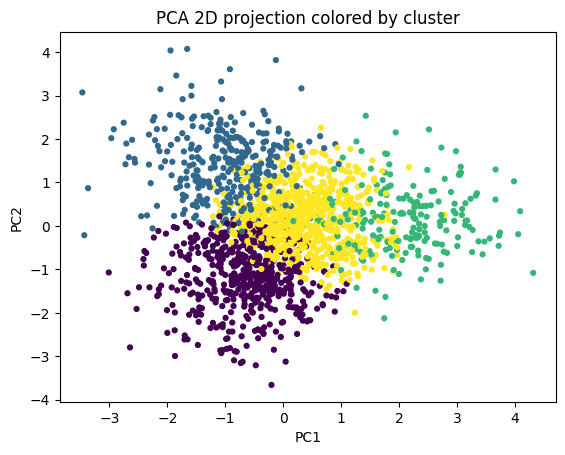

In [12]:
plt.figure()
plt.scatter(Z[:,0], Z[:,1], c=df["cluster"], s=12)
plt.title("PCA 2D projection colored by cluster")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


## 8) Optional: sanity-check clusters vs labels (NOT for training)

You may *inspect* how clusters relate to `purchase` **after** clustering to understand business meaning.

**Warning:** this is **not** “ground truth” for clustering quality, but can help interpret segments.


In [13]:
df.groupby("cluster")["purchase"].mean().round(3)


cluster
0    0.605
1    0.647
2    0.556
3    0.456
Name: purchase, dtype: float64

## 9) Write your evaluation story (memo outline)

Paste this into a 1-page memo:

1) **Stakeholder question:** What decision could this clustering support?
2) **Data:** What does a “session” represent? Any limitations?
3) **Method:** Preprocessing, K choice, and why K-Means is acceptable here.
4) **Results:** cluster sizes + 2–3 features that distinguish clusters; PCA plot.
5) **Confidence:** what checks you did (silhouette, stability by rerun, etc.)
6) **Risks:** bias/coverage, privacy, and how you would monitor drift.
7) **Next step:** what you’d collect or test next week.
